In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [21]:
def totalmass(filename,Mdisc):
    """
    Inputs:
    
    filename:  file being used to read to get the mass accretion 
    Mdisc:  total mass of disc initially before sim runs 

    Output:

    totalm: total mass of disc mass during sim
    """
    file = np.loadtxt(filename)
    mass_acc1 = file[:,20]
    mass_acc2 = file[:,21]
    initialmass = np.full(mass_acc1.shape,Mdisc)

    totalm = initialmass - mass_acc1 - mass_acc2
    return totalm

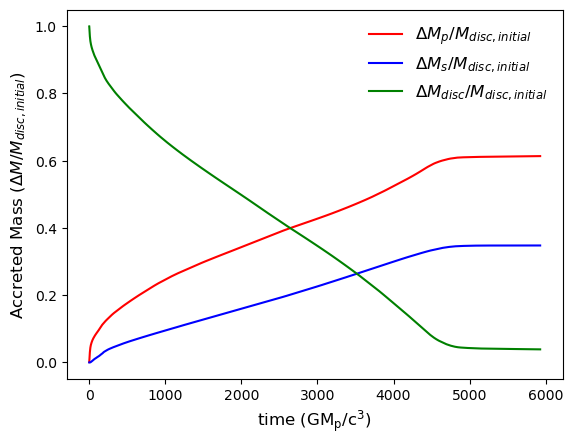

In [70]:
#don't forget to change titles when changing data and file names.
file = "C:/Users/tomsh/OneDrive - University of Leeds/year 4/Accretion disc/Semester 2/Week6/alpha_0.005_resol1mill/gwdisc01_al005r1mill.ev"
filenp= np.loadtxt(file)
mass_acc1 = filenp[:,20]
mass_acc2 = filenp[:,21]
totmass = totalmass(file,0.1)
time1 = filenp[:,0]
plt.plot(time1,mass_acc1/0.1, '-', color = 'red', label = r'$\Delta{M_p}/M_{disc,initial}$')
plt.plot(time1,mass_acc2/0.1,'-',color = 'blue',label = r'$\Delta{M_s}/M_{disc,initial}$')
plt.plot(time1,totmass/0.1,'-', color = 'green',label = r'$\Delta{M_{disc}}/M_{disc,initial}$')
plt.xlabel(r'time ($\mathrm{GM_p/c^3}$)',fontsize='large')
plt.ylabel(r'Accreted Mass ($\Delta{M}/M_{disc,initial}$)',fontsize='large')
#plt.title(r"accumalative accreted mass across time resol 1 million $\alpha_{SS}=0.005$")
plt.legend(frameon=False,fontsize='large')
plt.savefig("Accreted_mass_across_time_resol1mill_alpha_0.005_imp.pdf",bbox_inches='tight')
plt.show()

In [58]:
pd.DataFrame(file1)

,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
0,0.00000,0.018595,0.000212,0.0,0.037216,0.056022,0.0,0.000053,0.165526,0.530546,...,0.610116,-4.239133e-21,-7.418482e-21,0.000000e+00,2.733752e-19,0.165659,0.000092,0.000000,0.000094,0.000094
1,0.15625,0.018593,0.000212,0.0,0.037212,0.056016,0.0,0.000056,0.165515,0.444741,...,0.610109,2.050827e-05,8.088066e-05,2.068876e-10,4.897987e-07,0.165659,0.000100,0.000000,0.000102,0.000102
2,0.46875,0.018576,0.000212,0.0,0.037176,0.055964,0.0,0.000083,0.165415,0.214093,...,0.610050,8.365417e-05,2.804986e-04,5.340075e-09,7.596418e-07,0.165659,0.000171,0.000000,0.000172,0.000172
3,0.93750,0.018514,0.000212,0.0,0.037049,0.055775,0.0,0.000108,0.165057,0.140185,...,0.609805,2.382542e-04,7.218684e-04,-2.488256e-09,6.138282e-06,0.165659,0.000424,0.000000,0.000425,0.000426
4,1.87500,0.018387,0.000212,0.0,0.036793,0.055393,0.0,0.000110,0.164340,0.155832,...,0.609262,5.292956e-04,1.708774e-03,-8.735005e-08,1.868445e-05,0.165659,0.000928,0.000000,0.000931,0.000933
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3014,5900.00000,0.000522,0.000212,0.0,0.001046,0.001779,0.0,0.000018,0.010540,0.000409,...,0.466081,4.156509e-01,-1.146275e-01,-8.669904e-04,1.000786e-03,0.160175,0.059982,0.035199,0.095197,0.081270
3015,5910.00000,0.000522,0.000212,0.0,0.001046,0.001780,0.0,0.000015,0.010539,0.000408,...,0.466168,3.826163e-01,-1.082724e-01,-3.150606e-04,9.842705e-04,0.160175,0.059983,0.035199,0.095197,0.081270
3016,5911.25000,0.000522,0.000212,0.0,0.001046,0.001780,0.0,0.000015,0.010539,0.000428,...,0.466189,3.789935e-01,-1.098398e-01,-2.712634e-04,9.829836e-04,0.160175,0.059983,0.035199,0.095197,0.081270
3017,5913.75000,0.000522,0.000212,0.0,0.001046,0.001780,0.0,0.000014,0.010539,0.000398,...,0.466220,3.728627e-01,-1.139997e-01,-2.205693e-04,9.814472e-04,0.160175,0.059983,0.035199,0.095197,0.081269


In [59]:
def Mass_Acc_rate(M,time,N=50):
    """
    input:
    
    M - mass accreted onto hole at a certain time
    t - the time within the simulation in code units

    Reads data points and subtracts the previous value from the current datapoint to find the mass 
    accretion rate at that current time

    output:
    Returns the mass accretion rate of a black hole 
    """

    dM = M[N:] - M[:-N]
    dt = time[N:] - time[:-N]
    
    
    #dt = np.diff(time)
    #dM = np.diff(M)

    Mdot = dM / dt
    #t_mid = 0.5 * (time[1:] + time[:-1])
    t_mid = 0.5 * (time[N:] + time[:-N])

    return t_mid, Mdot
    
    

In [60]:
def Mass_acc_rate_graph_Primary(filename,Mdisc,N=50):
    """
    inputs:
    filename: file that is to be read for data. HAS to be a gwdisc.ev file or function reads wrong column
    Mdisc: mass of the accretion disc that will be used to normalise data
    
    outputs:
    t_mid: found in previous function. Average time for the accreted mass rate so it plots better
    Mdotnorm: normalised Accretion rate 

    info:This is done for the primary due to different columns for data
    """
    file = np.loadtxt(filename)
    mass_acc1 = file[:,20]
    
    time = file[:,0]
    t_mid, Mdot = Mass_Acc_rate(mass_acc1,time, N)
    Mdotnorm = Mdot/Mdisc
    return t_mid, Mdotnorm

In [61]:
def Mass_acc_rate_graph_Secondary(filename, Mdisc,N=50):
    """
    inputs:
    filename: file that is to be read for data. HAS to be a gwdisc.ev file or function reads wrong column
    Mdisc: mass of the accretion disc that will be used to normalise data
    
    outputs:
    t_mid: found in previous function. Average time for the accreted mass rate so it plots better
    Mdotnorm: normalised Accretion rate 

    info:This is done for the secondary due to different columns for data
    """
    file = np.loadtxt(filename)
    mass_acc2 = file[:,21]
    
    time = file[:,0]
    t_mid, Mdot2 = Mass_Acc_rate(mass_acc2,time)
    Mdotnorm2 = Mdot2/Mdisc
    return t_mid, Mdotnorm2

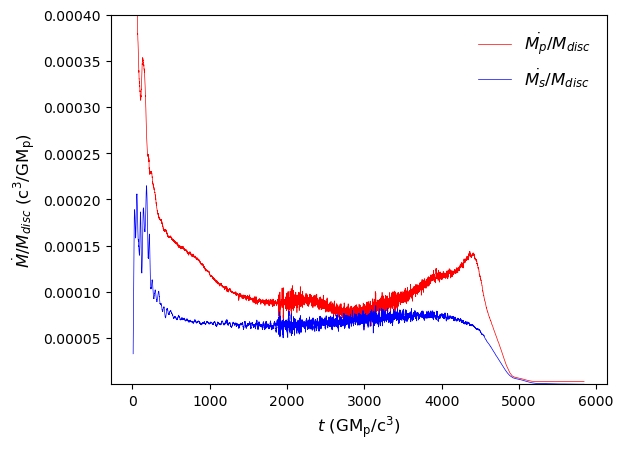

In [72]:
#don't forget to change titles when changing data and file names.
#limits should also be changed.
#file = "C:/Users/tomsh/OneDrive - University of Leeds/year 4/Accretion disc/Semester 2/Week7/alpha005_R2_02/gwdisc01_R2_02.ev"
tmidP, MdotP = Mass_acc_rate_graph_Primary(file,0.1) #change the disc file according to the data you are looking for
tmidS, MdotS = Mass_acc_rate_graph_Secondary(file,0.1) #change the disc file according to the data you are looking for
plt.plot(tmidP, MdotP, '-', color = 'red', linewidth = 0.5, label = r"$\dot{M_p}/M_{disc}$")
plt.plot(tmidS, MdotS, '-', color = 'blue', linewidth = 0.5, label = r"$\dot{M_s}/M_{disc}$")
plt.ylabel(r"$\dot{M}$/$M_{disc}$ ($\mathrm{c^3/GM_p}$)",fontsize='large')
plt.xlabel (r"$t$ ($\mathrm{GM_p/c^3}$)",fontsize='large')
plt.ylim(10**(-8),0.0004)
plt.legend(frameon=False,fontsize='large')
plt.savefig("Accretion_rate_across_time_al005_r1mill.pdf", bbox_inches='tight')
plt.show()

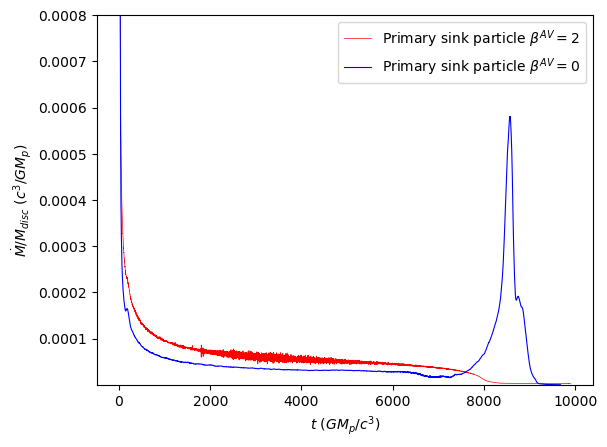

In [32]:
file2 = "C:/Users/tomsh/OneDrive - University of Leeds/year 4/Accretion disc/Semester 2/Week3/Cer_normal/gwdisc01_cer.ev"
file3 = "C:/Users/tomsh/OneDrive - University of Leeds/year 4/Accretion disc/Semester 2/Week4/Cerioli_resol2mill/gwdisc01_cer2mill.ev"
tmidP, MdotP = Mass_acc_rate_graph_Primary(file2,0.01) #change the disc file according to the data you are looking for
tmidP2, MdotP2 = Mass_acc_rate_graph_Primary(file3,1) #change the disc file according to the data you are looking for
plt.plot(tmidP, MdotP, '-', color = 'red', linewidth = 0.5, label = r"Primary sink particle $\beta^{AV}=2$")
plt.plot(tmidP2, MdotP2, '-', color = 'blue', linewidth = 0.8, label = r"Primary sink particle $\beta^{AV}=0$")
plt.ylabel("$\dot{M}$/$M_{disc}$ ($c^3$/$GM_p$)")
plt.xlabel ("$t$ ($GM_p$/$c^3$)")
plt.ylim(10**(-8),0.0008)

plt.legend()

plt.show()
plt.savefig("Accretion_rate_across_time_beta_primaries.png")

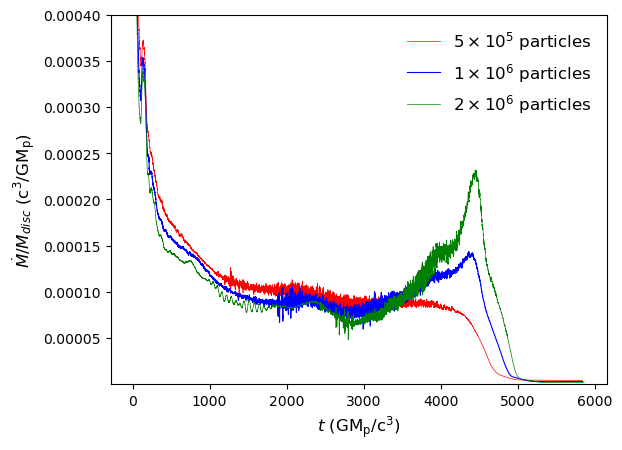

In [74]:
file4 = "C:/Users/tomsh/OneDrive - University of Leeds/year 4/Accretion disc/Semester 2/Week9/alpha_005_500r/gwdisc01.ev"
file5 = "C:/Users/tomsh/OneDrive - University of Leeds/year 4/Accretion disc/Semester 2/Week6/alpha_0.005_resol1mill/gwdisc01_al005r1mill.ev"
file6 = "C:/Users/tomsh/OneDrive - University of Leeds/year 4/Accretion disc/Semester 2/Week7/alpha005_resol2mill/gwdisc01_al005r2mill.ev"
tmidP3, MdotP3 = Mass_acc_rate_graph_Primary(file4,0.1) #change the disc file according to the data you are looking for
tmidP4, MdotP4 = Mass_acc_rate_graph_Primary(file5,0.1) #change the disc file according to the data you are looking for
tmidP5, MdotP5 = Mass_acc_rate_graph_Primary(file6,0.1)
plt.plot(tmidP3, MdotP3, '-', color = 'red', linewidth = 0.5, label = r"$5 \times 10^5$ particles")
plt.plot(tmidP4, MdotP4, '-', color = 'blue', linewidth = 0.8, label = r"$1 \times 10^6$ particles")
plt.plot(tmidP5, MdotP5, '-', color = 'green',linewidth = 0.5, label = r"$2 \times 10^6$ particles")
plt.ylabel(r"$\dot{M}$/$M_{disc}$ ($\mathrm{c^3/GM_p}$)",fontsize='large')
plt.xlabel (r"$t$ ($\mathrm{GM_p/c^3}$)",fontsize='large')
plt.ylim(10**(-8),0.0004)

plt.legend(frameon=False,fontsize='large')
plt.savefig("Accretion_rate_across_time_resolution_diff_imp.pdf", bbox_inches='tight')
plt.show()

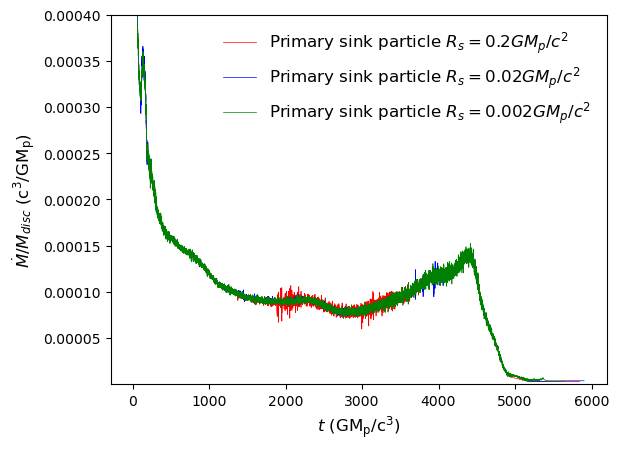

In [75]:
file7 = "C:/Users/tomsh/OneDrive - University of Leeds/year 4/Accretion disc/Semester 2/Week6/alpha_0.005_resol1mill/gwdisc01_al005r1mill.ev"
file8 = "C:/Users/tomsh/OneDrive - University of Leeds/year 4/Accretion disc/Semester 2/Week7/alpha005_R2_02/gwdisc01_R2_02.ev"
file9 = "C:/Users/tomsh/OneDrive - University of Leeds/year 4/Accretion disc/Semester 2/Week9/alpha_005_R2_002/gwdisc01.ev"
tmidP, MdotP = Mass_acc_rate_graph_Primary(file7,0.1) #change the disc file according to the data you are looking for
tmidP2, MdotP2 = Mass_acc_rate_graph_Primary(file8,0.1) #change the disc file according to the data you are looking for
tmidP3, MdotP3 = Mass_acc_rate_graph_Primary(file9,0.1,500)
plt.plot(tmidP, MdotP, '-', color = 'red', linewidth = 0.5, label = r"Primary sink particle $R_{s}=0.2GM_p/c^2$")
plt.plot(tmidP2, MdotP2, '-', color = 'blue', linewidth = 0.5, label = r"Primary sink particle $R_{s}=0.02GM_p/c^2$")
plt.plot(tmidP3, MdotP3, '-', color = 'green', linewidth =0.5, label = r"Primary sink particle $R_{s}=0.002GM_p/c^2$")
plt.ylabel(r"$\dot{M}$/$M_{disc}$ ($\mathrm{c^3/GM_p}$)",fontsize='large')
plt.xlabel (r"$t$ ($\mathrm{GM_p/c^3}$)",fontsize='large')
plt.ylim(10**(-8),0.0004)

plt.legend(frameon=False, fontsize='large')
plt.savefig("Acc_rate_Differing_Radius_imp.pdf",bbox_inches='tight')
plt.show()

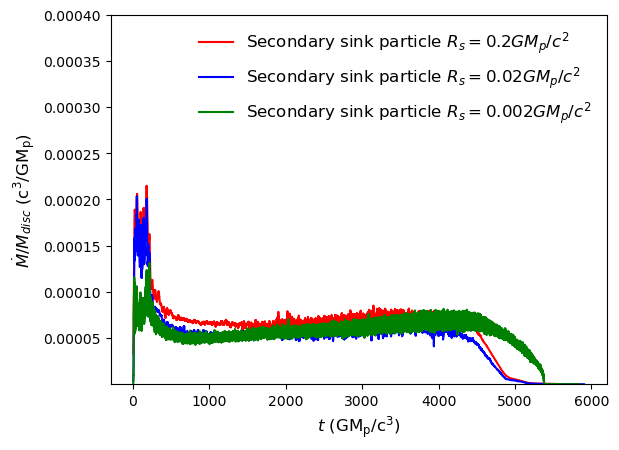

In [76]:
tmidS, MdotS = Mass_acc_rate_graph_Secondary(file7,0.1)
tmidS2, MdotS2 = Mass_acc_rate_graph_Secondary(file8,0.1)
tmidS3, MdotS3 = Mass_acc_rate_graph_Secondary(file9,0.1,200)
plt.plot(tmidS,MdotS,'-' ,color='red', label=r'Secondary sink particle $R_s=0.2GM_p/c^2$')
plt.plot(tmidS2,MdotS2,'-' ,color='blue', label=r'Secondary sink particle $R_s=0.02GM_p/c^2$')
plt.plot(tmidS3,MdotS3,'-' ,color='green', label=r'Secondary sink particle $R_s=0.002GM_p/c^2$')
#plt.axvline(x=5928, color='black', label="merger time")
plt.ylabel(r"$\dot{M}$/$M_{disc}$ ($\mathrm{c^3/GM_p}$)",fontsize='large')
plt.xlabel (r"$t$ ($\mathrm{GM_p/c^3}$)",fontsize='large')
plt.ylim(10**(-8),0.0004)

plt.legend(frameon=False,fontsize='large')
plt.savefig("secondary_accretion_rate2_imp.pdf", bbox_inches='tight')
plt.show()

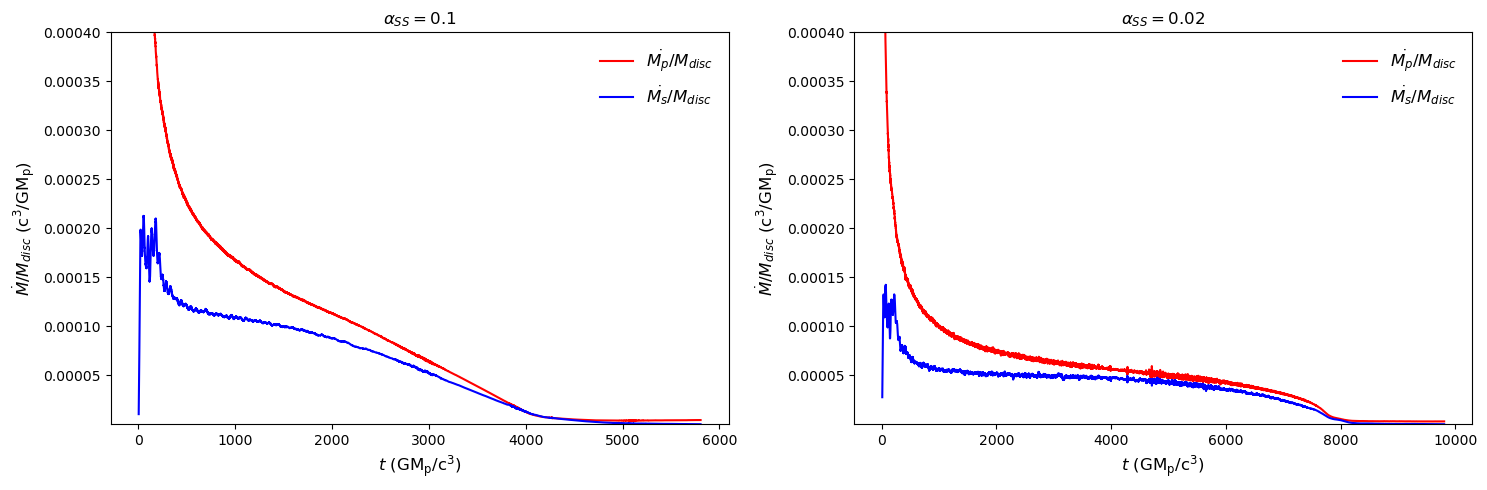

In [78]:
alpha1 = "C:/Users/tomsh/OneDrive - University of Leeds/year 4/Accretion disc/Semester 2/Week7/alpha1/gwdisc01_al1.ev"
alpha02 = "C:/Users/tomsh/OneDrive - University of Leeds/year 4/Accretion disc/Semester 2/Week6/alpha_0.02/gwdisc01.ev"
tmidP_al1, MdotP_al1 = Mass_acc_rate_graph_Primary(alpha1,0.1) #change the disc file according to the data you are looking for
tmidS_al1, MdotS_al1 = Mass_acc_rate_graph_Secondary(alpha1,0.1)
tmidP_al02, MdotP_al02 = Mass_acc_rate_graph_Primary(alpha02,0.1) #change the disc file according to the data you are looking for
tmidS_al02, MdotS_al02 = Mass_acc_rate_graph_Secondary(alpha02,0.1)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

ax1.plot(tmidP_al1, MdotP_al1,'-',color='red',label = r'$\dot{M_{p}}/M_{disc}$')
ax1.plot(tmidS_al1,MdotS_al1,'-',color='blue',label = r'$\dot{M_{s}}/M_{disc}$')
ax1.set_ylim(10**(-8),0.0004)
ax1.set_ylabel(r"$\dot{M}$/$M_{disc}$ ($\mathrm{c^3/GM_p}$)",fontsize='large')
ax1.set_xlabel (r"$t$ ($\mathrm{GM_p/c^3}$)",fontsize='large')
ax1.set_title(r"$\alpha_{SS}=0.1$",fontsize='large')
ax1.legend(frameon=False,fontsize='large')

ax2.plot(tmidP_al02, MdotP_al02, '-',color='red',label = r'$\dot{M_{p}}/M_{disc}$')
ax2.plot(tmidS_al02, MdotS_al02, '-', color = 'blue', label = r'$\dot{M_{s}}/M_{disc}$')
ax2.set_ylim(10**(-8),0.0004)
ax2.set_ylabel(r"$\dot{M}$/$M_{disc}$ ($\mathrm{c^3/GM_p}$)",fontsize='large')
ax2.set_xlabel (r"$t$ ($\mathrm{GM_p/c^3}$)",fontsize='large')
ax2.set_title(r"$\alpha_{SS}=0.02$",fontsize='large')
ax2.legend(frameon=False,fontsize='large')

plt.tight_layout()
plt.savefig("All_other_alpha_values_imp.pdf",  bbox_inches='tight')
plt.show()